## Preliminaries

Evaluation of xai methods on the test set according to the *localization* metrics from `Quantus`.

In [1]:
!pwd
#import os
#os.chdir('C:\\Users\\Teo\\Documents\\Projects') # equivalent to /teo on server

import sys
sys.path.append('./tf-explain/')
sys.path.append('./Quantus/Quantus/')
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import time
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers
import quantus
from quantus.metrics import *
from tf_explain.core.vanilla_gradients import VanillaGradients
from tf_explain.core.gradients_inputs import GradientsInputs
from tf_explain.core.integrated_gradients import IntegratedGradients

In [3]:
use_mini_dataset   = True
compress_B_lucorum = True
bees_subfolder = '22_species/' if compress_B_lucorum else '25_species/'

dataset_folder = 'Bees_Christian/' if use_mini_dataset else 'Bees/'
metafolder = './beexplainable/metafiles/'

BEES_PATH = '../data/data_lstudio/' + dataset_folder
IMAGES_PATH = metafolder + dataset_folder + 'images.txt'
MASKS_PATH = metafolder + dataset_folder + 'masks.txt'
IMAGES_LABELS_PATH = metafolder + dataset_folder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + dataset_folder + bees_subfolder + 'classes.txt'

W_H_PATH = metafolder + dataset_folder + 'widths_heights.txt'
BBOX_PATH = metafolder + dataset_folder + 'bounding_boxes.txt'
PART_CONTOURS = metafolder + dataset_folder + 'part_contours.npy'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/saliency/'

## Load images

In [4]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [5]:
batch_size = len(file_ids) # in case you want to compute metrics on all the test samples
img_height = img_width = 224
crop_to_bbox = False # whether to crop image to bbox
overlay_mask = False # whether to segment object and hide background

In [6]:
# Add extension to path if extra input transformation is enabled
input_form = 'raw'
if crop_to_bbox and not overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_bbox/'
    input_form = 'bbox'
elif not crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked/Whole/'
    input_form = 'mask'
elif crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked_bbox/'
    input_form = 'mask_bbox'
print(BEES_PATH)

../data/data_lstudio/Bees_Christian/


In [7]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image_and_mask(file_id, img_lookup, img_width, img_height,
                                                                  BEES_PATH, BEES_PATH[:-1] + '_masks/Whole/'),
                                          label)

In [8]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images (first item in the tuples, second is the mask)
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: ((normalization_layer(x[0]), x[1]), y))

Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `

In [9]:
for image_mask_batch, labels_batch in test_set.take(1):
    print(image_mask_batch[0].shape)
    print(image_mask_batch[1].shape)
    print(labels_batch[0])

(726, 224, 224, 3)
(726, 224, 224, 1)
tf.Tensor(0, shape=(), dtype=uint8)


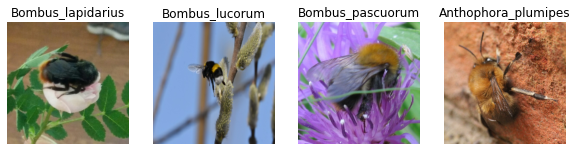

In [10]:
plt.figure(figsize = (10, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[0][i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

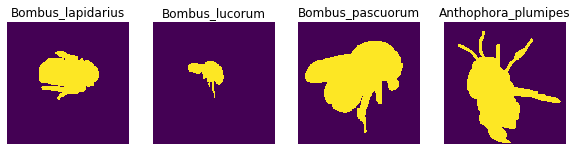

In [11]:
plt.figure(figsize = (10, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[1][i], interpolation = 'none')
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

## XAI

In [12]:
# Define initial parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-4, 1e-4

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
dataset_type = 'all' # model was trained on whole dataset and is now tested on mini dataset
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_raw' # model was trained on raw whole dataset
weights_file = MODELS_PATH + dataset_type + '/' + bees_subfolder + model_name + '/' + model_name + '.h5' # path to load weights from
print('Model loaded from ' + weights_file)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

Model loaded from ./beexplainable/models/all/22_species/ResNet50_iNat_raw/ResNet50_iNat_raw.h5


In [13]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

### tf-explain

In [14]:
# Define xai methods
explainers = [VanillaGradients(), GradientsInputs(), IntegratedGradients()] # these three work out of the box in Quantus
expl_names = ['Gradient', 'InputXGradient', 'IntegratedGradients']

### Quantus

In [15]:
# Construct batches of images, masks and predictions
for img_masks_batch, y_batch_true in test_set.as_numpy_iterator():
    x_batch = img_masks_batch[0]
    s_batch = img_masks_batch[1]
    y_batch_pred = np.argmax( model.predict(x_batch, verbose = 1), axis=-1 )
    break

23/23 [==============================] - 3s 39ms/step


In [16]:
# Generate attributions on the test set
a_batches, xai_methods = [], {}
start_time = time.time()
for i in range(len(explainers)):
    a_batch = (np.array(list( map(lambda x, y: explainers[i].explain(([x], None), model, y),
                                  x_batch,
                                  tf.cast(y_batch_pred, dtype=tf.int32)) ), dtype=float) / 255.)
    a_batches.append(a_batch)
    xai_methods[expl_names[i]] = a_batch # method names must be known by Quantus (check quantus.AVAILABLE_XAI_METHODS)
    print(expl_names[i] + ' done!')
print("--- %s seconds ---" % (time.time() - start_time))

Gradient done!
InputXGradient done!
IntegratedGradients done!
--- 205.49023389816284 seconds ---


In [17]:
print(f"x_batch: {np.shape(x_batch)}")
print(f"s_batch: {np.shape(s_batch)}")
print(f"a_batch: {np.shape(a_batches)}")
print(f"y_batch_pred: {np.shape(y_batch_pred)}")

x_batch: (726, 224, 224, 3)
s_batch: (726, 224, 224, 1)
a_batch: (3, 726, 224, 224)
y_batch_pred: (726,)


In [18]:
# Multiple methods for multiple metrics
disable_warnings = True

# Check quantus.available_metrics()['Localisation']
metrics = {"Pointing Game": quantus.PointingGame(**{'disable_warnings': disable_warnings}),
           "Attribution Localisation": quantus.AttributionLocalisation(**{'disable_warnings': disable_warnings}),
           "Top-K Intersection": quantus.TopKIntersection(**{'disable_warnings': disable_warnings}),
           "Relevance Rank Accuracy": quantus.RelevanceRankAccuracy(**{'disable_warnings': disable_warnings}),
           "Relevance Mass Accuracy": quantus.RelevanceRankAccuracy(**{'disable_warnings': disable_warnings}),
           "AUC": quantus.AUC(**{'disable_warnings': disable_warnings})}

start_time = time.time()
results = quantus.evaluate(evaluation_metrics=metrics,
                           explanation_methods=xai_methods,
                           model=model,
                           x_batch=x_batch,
                           y_batch=y_batch_pred,
                           s_batch=np.swapaxes(s_batch, 1, 3), # channel-first-format (turned into channel-last by quantus)
                           agg_func=np.mean,
                           metrics = metrics,
                           xai_methods = xai_methods,
                           **{"explain_func": quantus.explain, "normalise": False, "abs": False})

print("--- %s seconds ---" % (time.time() - start_time))
results





































--- 59.88187623023987 seconds ---


{'Gradient': {'Pointing Game': 0.9462809917355371,
  'Attribution Localisation': 0.29838796335045836,
  'Top-K Intersection': 0.3320482093663912,
  'Relevance Rank Accuracy': 0.304786850520799,
  'Relevance Mass Accuracy': 0.304786850520799,
  'AUC': 0.7156704839720857},
 'InputXGradient': {'Pointing Game': 0.9421487603305785,
  'Attribution Localisation': 0.2550578056090607,
  'Top-K Intersection': 0.28069972451790637,
  'Relevance Rank Accuracy': 0.25870783158724736,
  'Relevance Mass Accuracy': 0.25870783158724736,
  'AUC': 0.6671096245325662},
 'IntegratedGradients': {'Pointing Game': 0.9297520661157025,
  'Attribution Localisation': 0.31682364126381557,
  'Top-K Intersection': 0.35470247933884297,
  'Relevance Rank Accuracy': 0.3231328553227531,
  'Relevance Mass Accuracy': 0.3231328553227531,
  'AUC': 0.7296814454646169}}